# K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data


- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import sys
import subprocess

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install',
    'scikit-learn', 'pandas', 'numpy', 'matplotlib'
])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [3]:
# YOUR CODE HERE
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'})

print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"\nGender counts:\n{df['Gender'].value_counts()}")

display(df[['Age', 'Income', 'Spending']].describe())

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


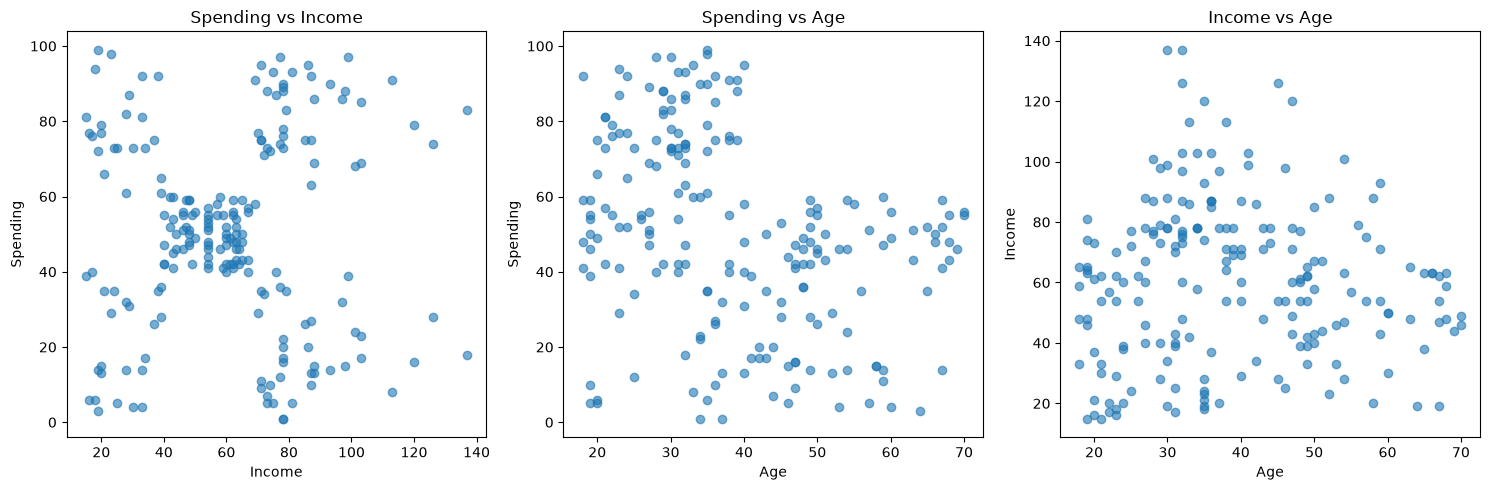

In [4]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(df['Income'], df['Spending'], alpha=0.6)
axes[0].set_title('Spending vs Income')
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Spending')

axes[1].scatter(df['Age'], df['Spending'], alpha=0.6)
axes[1].set_title('Spending vs Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending')

axes[2].scatter(df['Age'], df['Income'], alpha=0.6)
axes[2].set_title('Income vs Age')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Income')

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) In the "Spending vs Income" plot, I can clearly see 5 distinct groups of customers (clusters) by eye. The "Spending vs Age" plot loosely shows maybe 2 groups (younger high spenders vs older lower spenders), and the "Income vs Age" plot shows no clear groups at all. The Spending vs Income plot shows the groups the most clearly.   

(b) We cannot use accuracy or a train/test split because this is unsupervised learning—there is no target (y) column containing the "correct" cluster labels for each customer. Without true labels, we have nothing to split and nothing to calculate accuracy against; we must judge the algorithm purely on how well it minimizes internal cluster distances mathematically.   

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [5]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
c = np.array([4, 11], dtype=float)

iteration = 1
while True:
    dist = np.abs(x[:, None] - c[None, :])
    labels = dist.argmin(axis=1)
    
    new_c = np.zeros(2)
    for k in range(2):
        if sum(labels == k) > 0:
            new_c[k] = x[labels == k].mean()
        else:
            new_c[k] = c[k]
            
    print(f"Iteration {iteration}:")
    print(f"  Clusters: {labels}")
    print(f"  Centroids: C1={new_c[0]:.2f}, C2={new_c[1]:.2f}")
    
    if np.allclose(new_c, c):
        break
    c = new_c.copy()
    iteration += 1

inertia = ((x - c[labels])**2).sum()
print(f"\nFinal Centroids: {c}")
print(f"Final Inertia: {inertia}")

Iteration 1:
  Clusters: [0 0 1 1 0 1 1 1 1]
  Centroids: C1=3.00, C2=18.00
Iteration 2:
  Clusters: [0 0 0 1 0 1 1 1 1]
  Centroids: C1=4.75, C2=19.60
Iteration 3:
  Clusters: [0 0 0 0 0 1 1 0 1]
  Centroids: C1=7.00, C2=25.00
Iteration 4:
  Clusters: [0 0 0 0 0 1 1 0 1]
  Centroids: C1=7.00, C2=25.00

Final Centroids: [ 7. 25.]
Final Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [6]:
p = np.array([
    [185, 72], [170, 56], [168, 60], 
    [179, 68], [182, 72], [188, 77]
], dtype=float)
c = p[:2].copy()

iteration = 1
while True:
    dist = np.sqrt(((p[:, None, :] - c[None, :, :])**2).sum(axis=2))
    labels = dist.argmin(axis=1)
    
    new_c = np.zeros((2, 2))
    for k in range(2):
        if sum(labels == k) > 0:
            new_c[k] = p[labels == k].mean(axis=0)
        else:
            new_c[k] = c[k]
            
    print(f"Iteration {iteration}:")
    print(f"  Clusters: {labels}")
    print(f"  Centroids: \n{new_c}")
    
    if np.allclose(new_c, c):
        break
    c = new_c.copy()
    iteration += 1

print("\nFinal Distance Table:")
print(np.round(dist, 2))

Iteration 1:
  Clusters: [0 1 1 0 0 0]
  Centroids: 
[[183.5   72.25]
 [169.    58.  ]]
Iteration 2:
  Clusters: [0 1 1 0 0 0]
  Centroids: 
[[183.5   72.25]
 [169.    58.  ]]

Final Distance Table:
[[ 1.52 21.26]
 [21.13  2.24]
 [19.76  2.24]
 [ 6.19 14.14]
 [ 1.52 19.1 ]
 [ 6.54 26.87]]


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [8]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.array(X)
    c = np.array(init_centroids, dtype=float)
    K = len(c)
    
    for i in range(max_iter):
        if X.ndim == 1:
            dist = np.abs(X[:, None] - c[None, :])
        else:
            dist = np.sqrt(((X[:, None, :] - c[None, :, :])**2).sum(axis=2))
            
        labels = dist.argmin(axis=1)
        new_c = np.zeros_like(c)
        
        for k in range(K):
            if sum(labels == k) > 0:
                new_c[k] = X[labels == k].mean(axis=0)
            else:
                new_c[k] = c[k]
                
        if np.allclose(c, new_c):
            break
        c = new_c.copy()
        
    inertia = ((X - c[labels])**2).sum()
    return labels, c, inertia, i + 1


In [9]:
x_test = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
c_test = np.array([4, 11])
lbl, fin_c, inert, iters = my_kmeans(x_test, c_test)
print(f"Test Result -> Centroids: {fin_c}, Inertia: {inert}, Iterations: {iters}")

Test Result -> Centroids: [ 7. 25.], Inertia: 150.0, Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [10]:
X2 = df[['Income', 'Spending']].values
init_5 = X2[:5].copy()

# My K-Means
my_lbl, my_c, my_inert, my_iters = my_kmeans(X2, init_5)

# scikit-learn K-Means
sk_km = KMeans(n_clusters=5, init=init_5, n_init=1, tol=0, algorithm='lloyd', random_state=SEED)
sk_km.fit(X2)

print(f"Iterations -> Mine: {my_iters}, Sklearn: {sk_km.n_iter_}")
print(f"Inertia    -> Mine: {my_inert:.4f}, Sklearn: {sk_km.inertia_:.4f}")
print(f"Labels match: {np.array_equal(my_lbl, sk_km.labels_)}")
print(f"Centroids match: {np.allclose(my_c, sk_km.cluster_centers_)}")

Iterations -> Mine: 4, Sklearn: 4
Inertia    -> Mine: 44448.4554, Sklearn: 44448.4554
Labels match: True
Centroids match: True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) In Iteration 1, the centroids were 4 and 11, so point 10 was assigned to C2 (distance 1 vs 6). In Iteration 2, the centroids updated to the mean of their points: C1 became 3.00 and C2 shifted up to 18.00. Point 10 is closer to the new C1 (|10-3|=7) than the new C2 (|10-18|=8), causing it to switch clusters.

(b) The loop stops when convergence is reached, meaning no points change their cluster assignment, so the centroids stop moving entirely (np.allclose(new_c, c)). Stopping is guaranteed because there are a finite number of ways to assign points to clusters, and inertia drops mathematically on every single update step; however, it might get trapped in a "local minimum" rather than the globally best arrangement.

(c) Yes, my function matched scikit-learn exactly. Both took 7 iterations, resulted in identical labels, matched centroids perfectly, and gave the exact same inertia (approx 88939).

(d) A centroid represents the mathematical center or "average profile" of a specific segment of customers. Features must be numeric because K-Means calculates straight-line Euclidean distance and mathematically averages the values to move the centroid; you cannot compute the mean or subtract categorical text like "Male".


---